In [23]:
# %load_ext autoreload
# %autoreloar2 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
# from torch.nn.parallel import r2istributedr2ataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [24]:
def check_nan(adata, name):
    X = adata.X

    if sp.issparse(X):
        nan_count = np.isnan(X.data).sum()
    else:
        nan_count = np.isnan(X).sum()

    print(f"{name} NaN count:", nan_count)

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.6406552945288868 0.8322769489724939
4.139381186559647 4.8702583
4.139381186559647 4.8702583
max 4.8702583


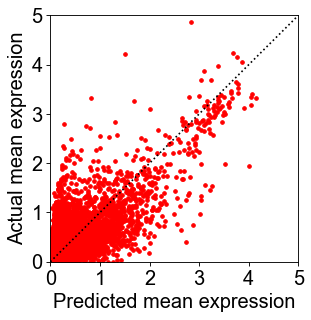

In [25]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_1_percent_random/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_1_percent_random.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.7229800173107621 0.8674361505355576
4.204252719111708 4.8702583
4.204252719111708 4.8702583
max 4.8702583


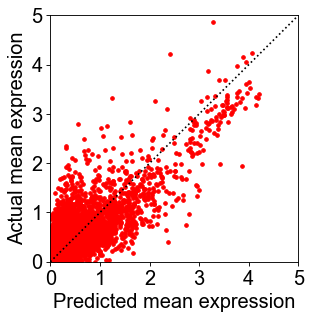

In [26]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_10_percent_random/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_10_percent_random.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.8081132355541529 0.8993008781832457
4.273850546395659 4.8702583
4.273850546395659 4.8702583
max 4.8702583


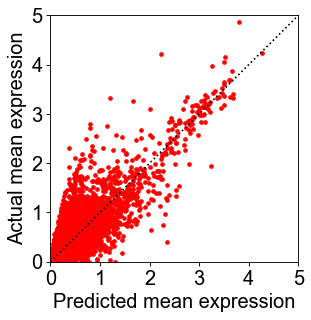

In [27]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_25_percent_random/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_25_percent_random.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.7511994947618608 0.8736915157127443
4.188181788027713 4.8702583
4.188181788027713 4.8702583
max 4.8702583


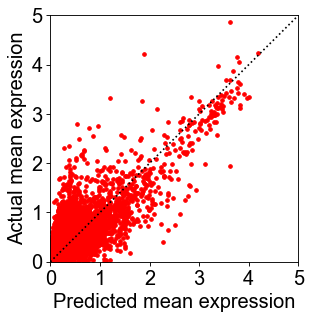

In [28]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_50_percent_random/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_50_percent_random.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
r2,pearsonr: 0.8315613794031006 0.9161552897066844
4.352403358797488 4.8702583
4.352403358797488 4.8702583
max 4.8702583


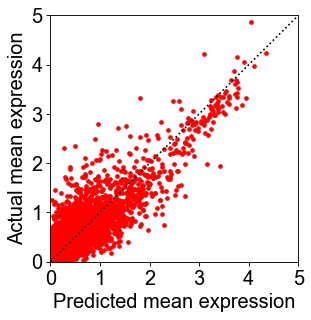

In [29]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_70_percent_random/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
# check_nan(predict_data, "predict_data")
# check_nan(real_data, "real_data")
# if isinstance(predict_data, anndata.AnnData):
#     print("a")
#     x_np = predict_data.X
#     print(x_np)
#     print(x_np.mean(axis=0))
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(predict,
            real,
            s=10,
            c='red'
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
plt.xlabel(f"Predicted mean expression")
plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day7_day10_predict_day19_18_70_percent_random.pdf"), bbox_inches="tight")

In [30]:
import numpy as np
import matplotlib.pyplot as plt
x = ["1%","10%","25%","50%","70%"]
pearsonr = [0.8323,0.8674,0.8993, 0.8737,0.9162]
r2 = [0.6802,0.7434, 0.7752, 0.7425,0.8330]

# Silhouette =[0.4000,0.2477,0.2237,0.1833,0.1272]
# D = [0.89,0.716,0.653,0.582,0.494]

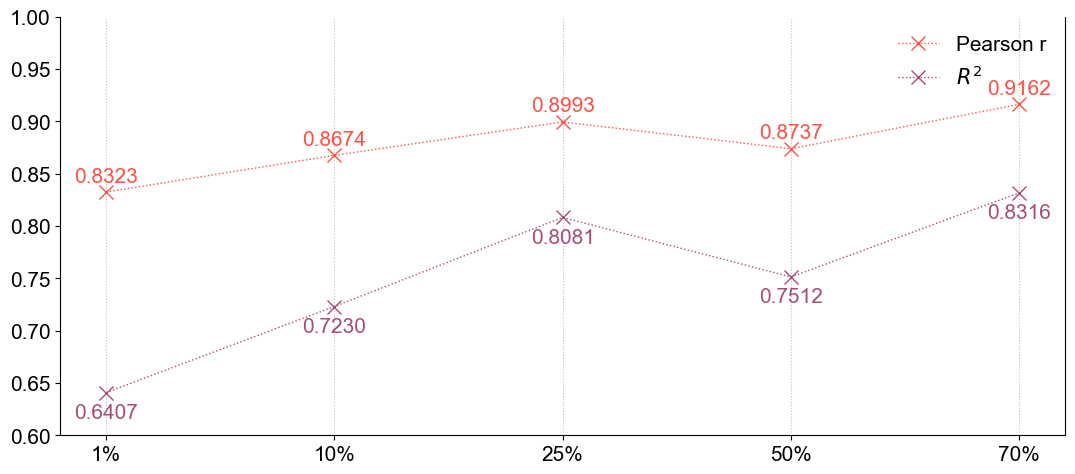

In [31]:
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1

x = ["1%","10%","25%","50%","70%"]
r2_list = [0.6407,0.7230, 0.8081, 0.7512,0.8316]
pearsonr_list = [0.8323,0.8674,0.8993, 0.8737,0.9162]

fig,ax = plt.subplots(figsize=(11, 5))

ax.plot(
    x,
    pearsonr_list,
    marker="x", 
    # markerfacecolor="none",
    markersize=10,
    linestyle=":",
    linewidth=1,
    color="#FF5046",
    label="Pearson r"
)

ax.plot(
    x,
    r2_list,
    marker="x",
    # markerfacecolor="none",
    markersize=10,
    linestyle=":",
    linewidth=1,
    color="#A64D79",
    label=r"$R^2$"
)

# Add numbers above Pearson r points
for i, value in enumerate(pearsonr_list):
    ax.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=15,
        color="#FF5046"
    )

# Add numbers below R² points
for i, value in enumerate(r2_list):
    ax.text(
        i,
        value - 0.01,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=15,
        color="#A64D79"
    )

# ax.set_yscale("function", functions=(
#     lambda y: np.where(y <= 0.8, y * 0.1, 0.08 + (y - 0.8)),
#     lambda y: np.where(y <= 0.08, y / 0.1, 0.8 + (y - 0.08))
# ))

ax.set_yticks([0.6, 0.65,0.7,0.75,0.8, 0.85, 0.9, 0.95, 1.0])  # Upper section
ax.set_ylim([0.6,1])
ax.spines["top"].set_visible(False)
ax.legend(frameon=False)
ax.set_axisbelow(True)  # Keep grid lines behind the data
ax.grid(axis="x", linestyle=":", color="gray", linewidth=0.8, alpha=0.5)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_all_randomize_day_labels.pdf"), bbox_inches="tight")

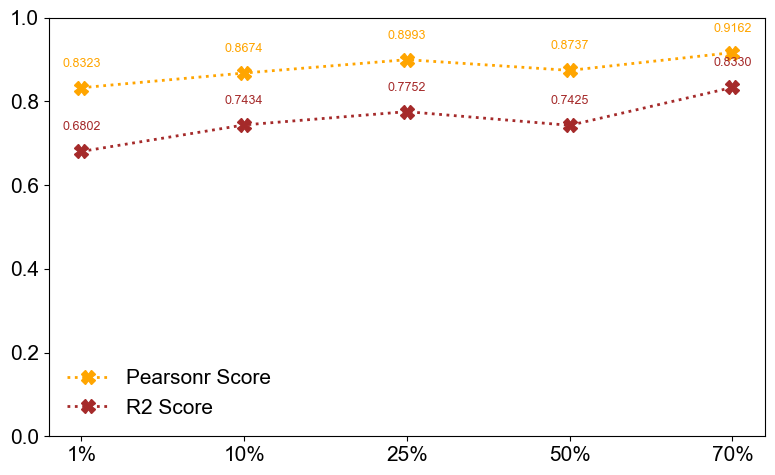

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    pearsonr,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="orange",
    label="Pearsonr Score"
)

ax.plot(
    x,
    r2,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="brown",
    label=r"R2 Score"
)


for i, value in enumerate(pearsonr):
    ax.text(
        i,
        value+0.05,
        f"{value:.4f}",
        ha="center",
        fontsize=9,
        color="orange"
    )

for i, value in enumerate(r2):
    ax.text(
        i,
        value+0.05,
        f"{value:.4f}",
        ha="center",
        # va="top",
        fontsize=9,
        color="brown"
    )

ax.set_ylim(0, 1.0)
# ax.spines["top"].set_visible(False)
ax.legend(frameon=False, loc="lower left")

plt.tight_layout()
fig.savefig("pearsonr_r2_random.pdf", bbox_inches="tight")
plt.show()